### RAG with Persistent Memory from Langhgraph

In [53]:
import os 
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

from langchain.chat_models import init_chat_model

llm = init_chat_model("openai:gpt-4o")

llm


ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-openai': '1.6.7'}}, profile={'name': 'GPT-4o', 'release_date': '2024-05-13', 'last_updated': '2024-08-06', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x000001F50308C410>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000001F50308C7D0>, root_client=<openai.OpenAI object at 0x000001F50308C190>, roo

In [54]:
import truststore
truststore.inject_into_ssl()

In [55]:
from langchain_openai import OpenAIEmbeddings
embeddings = OpenAIEmbeddings()
embeddings

OpenAIEmbeddings(client=<openai.resources.embeddings.Embeddings object at 0x000001F50308D090>, async_client=<openai.resources.embeddings.AsyncEmbeddings object at 0x000001F50308D950>, model='text-embedding-ada-002', dimensions=None, deployment='text-embedding-ada-002', openai_api_version=None, openai_api_base=None, openai_api_type=None, openai_proxy=None, embedding_ctx_length=8191, openai_api_key=SecretStr('**********'), openai_organization=None, allowed_special=None, disallowed_special=None, chunk_size=1000, max_retries=2, request_timeout=None, headers=None, tiktoken_enabled=True, tiktoken_model_name=None, show_progress_bar=False, model_kwargs={}, skip_empty=False, default_headers=None, default_query=None, retry_min_seconds=4, retry_max_seconds=20, http_client=None, http_async_client=None, check_embedding_ctx_length=True)

In [56]:
# Document Ingestion and Processing

import bs4
from langsmith import Client
from langchain_community.document_loaders import WebBaseLoader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from typing import List, TypedDict


In [57]:
loader = WebBaseLoader(
    web_paths=("https://lilianweng.github.io/posts/2023-06-23-agent/",),
    bs_kwargs=dict(
        parse_only= bs4.SoupStrainer(
            class_=("post-content", "post-title", "post-header")
        )
    )
)

docs = loader.load()
docs

ConnectionError: HTTPSConnectionPool(host='lilianweng.github.io', port=443): Max retries exceeded with url: /posts/2023-06-23-agent/ (Caused by NameResolutionError("HTTPSConnection(host='lilianweng.github.io', port=443): Failed to resolve 'lilianweng.github.io' ([Errno 11001] getaddrinfo failed)"))

In [ ]:
##chunking
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)
chunked_docs = text_splitter.split_documents(docs)
chunked_docs

[Document(metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/'}, page_content='LLM Powered Autonomous Agents\n    \nDate: June 23, 2023  |  Estimated Reading Time: 31 min  |  Author: Lilian Weng\n\n\nBuilding agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview#\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refi

In [ ]:
## Vector Store

from langchain_community.vectorstores import FAISS
vectorstore = FAISS.from_documents(
    documents=chunked_docs, 
    embedding=embeddings
)

print(f"Vector store created with {vectorstore.index.ntotal} vectors")


Vector store created with 63 vectors


In [ ]:
from langchain.tools import tool

@tool
def retrieve(query:str) :
    """Retrieve the information releated to the query"""
    retrieved_docs = vectorstore.similarity_search(query, k=2)
    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\nContent: {doc.page_content}")
        for doc in retrieved_docs
    )
    return serialized, retrieved_docs





In [ ]:
from langchain_core.messages import SystemMessage
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

In [ ]:
# Step 1 : Generate an AI Message that may include a tool-call to be sent

def query_or_respond(state: MessagesState):
    """Generate tool call for retrieval or respond."""
    llm_with_tools = llm.bind_tools([retrieve])
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

In [ ]:
# Step 2 : Execute the retrieval.
tools = ToolNode([retrieve])
tools

tools(tags=None, recurse=True, explode_args=False, func_accepts={'config': ('N/A', <class 'inspect._empty'>), 'runtime': ('N/A', <class 'inspect._empty'>)}, _tools_by_name={'retrieve': StructuredTool(name='retrieve', description='Retrieve the information releated to the query', args_schema=<class 'langchain_core.utils.pydantic.retrieve'>, func=<function retrieve at 0x000001F4FCDE7CC0>)}, _injected_args={'retrieve': _InjectedArgs(state={}, store=None, runtime=None, all_injected_keys=set(), _optional_state_args=set())}, _handle_tool_errors=<function _default_handle_tool_errors at 0x000001F4FCC914E0>, _messages_key='messages', _wrap_tool_call=None, _awrap_tool_call=None)

In [ ]:
# Step 3 : Generate a response using the retrieved content

def generate(state: MessagesState):
    """Generate answer."""
    recent_tool_messages = []
    for message in reversed(state["messages"]):
        if message.type == "tool":
            recent_tool_messages.append(message)
        else:
            break
    
    tool_messages = recent_tool_messages[::-1]
    docs_content = "\n\n".join(doc.content for doc in tool_messages)

    system_message_content = (
        "You are an assistant for question-answering tasks. "
        "Use the following pieces of retrieved context to answer "
        "the question. If you don't know the answer, say that you don't know. "
        "Also, use three sentences at most to keep the answer concise"
        "\n\n"
        f"{docs_content}"
    )

    conversation_messages = [
        message
        for message in state["messages"]
        if message.type in ("human", "system")
        or (message.type == "ai" and not message.tool_calls)
    ]

    prompt = [SystemMessage(content=system_message_content)] + conversation_messages
    response = llm.invoke(prompt)
    return {"messages": [response]}

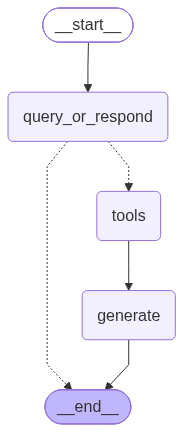

In [ ]:
# Build graph

graph_builder = StateGraph(MessagesState)

graph_builder.add_node("query_or_respond", query_or_respond)
graph_builder.add_node("tools", tools)
graph_builder.add_node("generate", generate)

graph_builder.set_entry_point("query_or_respond")
graph_builder.add_conditional_edges(
    "query_or_respond",
    tools_condition,
    {END:END, "tools": "tools"},
)

graph_builder.add_edge("tools", "generate")
graph_builder.add_edge("generate", END)

memory = MemorySaver()
graph = graph_builder.compile(checkpointer=memory)
graph



In [ ]:
# specify an ID for the thread
config = {"configurable" : {"thread_id": "NM2509"}}

In [ ]:
input_message="Hello"
for step in graph.stream(
    {"messages": [{"role": "user", "content": input_message}]},
    stream_mode="values",
    config=config,
):
    step["messages"][-1].pretty_print()


================================ Human Message =================================

Hello
================================== Ai Message ==================================

Hello! How can I assist you today?


In [ ]:
input_message = "What is Task Decomposition?"

for step in graph.stream(
    {"messages": [{"role": "user", "content": input_message}]},
    stream_mode="values",
    config=config,
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

What is Task Decomposition?
================================== Ai Message ==================================
Tool Calls:
  retrieve (call_Sb543l5E4WQNM8P9WpYA3qXw)
 Call ID: call_Sb543l5E4WQNM8P9WpYA3qXw
  Args:
    query: Task Decomposition
================================= Tool Message =================================
Name: retrieve

('Source: {\'source\': \'https://lilianweng.github.io/posts/2023-06-23-agent/\'}\nContent: Component One: Planning#\nA complicated task usually involves many steps. An agent needs to know what they are and plan ahead.\nTask Decomposition#\nChain of thought (CoT; Wei et al. 2022) has become a standard prompting technique for enhancing model performance on complex tasks. The model is instructed to “think step by step” to utilize more test-time computation to decompose hard tasks into smaller and simpler steps. CoT transforms big tasks into multiple manageable tasks and shed 

In [60]:
input_message = "can you find another ways of doing it?"

for step in graph.stream(
    {"messages" : [{"role": "user", "content" : input_message}]},
    stream_mode = "values",
    config=config,
):

    step["messages"][-1].pretty_print()



================================ Human Message =================================

can you find another ways of doing it?
================================== Ai Message ==================================
Tool Calls:
  retrieve (call_II88NgHcV4lty34xsAEvcjZA)
 Call ID: call_II88NgHcV4lty34xsAEvcjZA
  Args:
    query: alternatives to Task Decomposition
================================= Tool Message =================================
Name: retrieve

('Source: {\'source\': \'https://lilianweng.github.io/posts/2023-06-23-agent/\'}\nContent: Component One: Planning#\nA complicated task usually involves many steps. An agent needs to know what they are and plan ahead.\nTask Decomposition#\nChain of thought (CoT; Wei et al. 2022) has become a standard prompting technique for enhancing model performance on complex tasks. The model is instructed to “think step by step” to utilize more test-time computation to decompose hard tasks into smaller and simpler steps. CoT transforms big tasks into multiple

In [61]:
### Conversation history
chat_history = graph.get_state(config).values["messages"]
for messages in chat_history:
    messages.pretty_print()


================================ Human Message =================================

Hello
================================== Ai Message ==================================

Hello! How can I assist you today?
================================ Human Message =================================

What is Task Decomposition?
================================== Ai Message ==================================
Tool Calls:
  retrieve (call_Sb543l5E4WQNM8P9WpYA3qXw)
 Call ID: call_Sb543l5E4WQNM8P9WpYA3qXw
  Args:
    query: Task Decomposition
================================= Tool Message =================================
Name: retrieve

('Source: {\'source\': \'https://lilianweng.github.io/posts/2023-06-23-agent/\'}\nContent: Component One: Planning#\nA complicated task usually involves many steps. An agent needs to know what they are and plan ahead.\nTask Decomposition#\nChain of thought (CoT; Wei et al. 2022) has become a standard prompting technique for enhancing model performance on complex tasks. Th

### ReAct Agent Architecture - Persistent Memory